In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import OrdinalEncoder #for OHE pd.getdummies

from sksurv.util import Surv #to create the target y in the format required by rsf (event, time)

# 1. Data Loading and Cleaning

In [60]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

In [61]:
print(df.shape)
print(df.columns.tolist())
print(df[['tenure', 'Churn']].head(10))

(7043, 21)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
   tenure Churn
0       1    No
1      34    No
2       2   Yes
3      45    No
4       2   Yes
5       8   Yes
6      22    No
7      10    No
8      28   Yes
9      62    No


In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [63]:
#Total Chargers is object str type - converting this to numeric float and setting any errors/ blank strings to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


print(df['TotalCharges'].isna().sum())  # prints 11 ie 11 are null

print(df[df['TotalCharges'].isna()]['tenure'].unique())  # the tenure of customers with blank total charges is 0 months. so we dropped them

df = df.dropna(subset=['TotalCharges'])
print(f"After dropping customers where total charges was null: {df.shape[0]} customers")  # should print 7032

11
[0]
After dropping customers where total charges was null: 7032 customers


In [64]:
df['Churn_flag'] = (df['Churn'] == 'Yes').astype(int)  # 1 = churned, 0 = active

print(f"Dataset: {df.shape[0]} customers, {df['Churn_flag'].mean():.1%} churn rate")
print(f"Tenure ranges from {df['tenure'].min()} to {df['tenure'].max()} months")

Dataset: 7032 customers, 26.6% churn rate
Tenure ranges from 1 to 72 months


In [65]:
# survival columns
print(df[['tenure', 'Churn_flag']].head(10))
print()

# sanity check
print("Churned:", df['Churn_flag'].sum())
print("Censored:", (df['Churn_flag'] == 0).sum())


   tenure  Churn_flag
0       1           0
1      34           0
2       2           1
3      45           0
4       2           1
5       8           1
6      22           0
7      10           0
8      28           1
9      62           0

Churned: 1869
Censored: 5163


In [66]:
print("\nChurn Proportions:", df['Churn'].value_counts(normalize=True))


Churn Proportions: Churn
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64


In [67]:
#dropping customer ID and Churn (becuase we have our new Churn col as 'Event' so we dont need this old col)

df = df.drop(columns=['customerID','Churn'])

---

# 2. Separating Features and Target columns

In [68]:
#separating features from labels - tenure and churn flag

X = df.drop(columns=['tenure','Churn_flag','TotalCharges'])

print(X.shape)
print(X.dtypes)

(7032, 17)
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
dtype: object


In [69]:
X.head(5)

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges
0,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85
1,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95
2,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85
3,Male,0,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30
4,Female,0,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70


### 2.1 One hot encoding of all categorical features. 

In [70]:
X = pd.get_dummies(X, drop_first=True) #replaces all str categorical cols with the respective 
#dummy cols depending on number of categories available for each feature. drop_first=true prevents linear combinations of cols = 1.

print(X.shape)
print(X.dtypes)



(7032, 28)
SeniorCitizen                              int64
MonthlyCharges                           float64
gender_Male                                 bool
Partner_Yes                                 bool
Dependents_Yes                              bool
PhoneService_Yes                            bool
MultipleLines_No phone service              bool
MultipleLines_Yes                           bool
InternetService_Fiber optic                 bool
InternetService_No                          bool
OnlineSecurity_No internet service          bool
OnlineSecurity_Yes                          bool
OnlineBackup_No internet service            bool
OnlineBackup_Yes                            bool
DeviceProtection_No internet service        bool
DeviceProtection_Yes                        bool
TechSupport_No internet service             bool
TechSupport_Yes                             bool
StreamingTV_No internet service             bool
StreamingTV_Yes                             bool
Streaming

In [71]:
# Find boolean columns - most of them have come from pd.getdummies
bool_cols = X.select_dtypes(include="bool").columns

# Convert only those columns to int (True -> 1, False -> 0)
X[bool_cols] = X[bool_cols].astype(int)


In [72]:
X.dtypes

SeniorCitizen                              int64
MonthlyCharges                           float64
gender_Male                                int64
Partner_Yes                                int64
Dependents_Yes                             int64
PhoneService_Yes                           int64
MultipleLines_No phone service             int64
MultipleLines_Yes                          int64
InternetService_Fiber optic                int64
InternetService_No                         int64
OnlineSecurity_No internet service         int64
OnlineSecurity_Yes                         int64
OnlineBackup_No internet service           int64
OnlineBackup_Yes                           int64
DeviceProtection_No internet service       int64
DeviceProtection_Yes                       int64
TechSupport_No internet service            int64
TechSupport_Yes                            int64
StreamingTV_No internet service            int64
StreamingTV_Yes                            int64
StreamingMovies_No i

In [73]:

X.head(10)

,SeniorCitizen,MonthlyCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,29.85,0,1,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,0,56.95,1,0,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,53.85,1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,42.30,1,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0
4,0,70.70,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
5,0,99.65,0,0,0,1,0,1,1,0,...,0,1,0,1,0,0,1,0,1,0
6,0,89.10,1,0,1,1,0,1,1,0,...,0,1,0,0,0,0,1,1,0,0
7,0,29.75,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
8,0,104.80,0,1,0,1,0,1,1,0,...,0,1,0,1,0,0,1,0,1,0
9,0,56.15,1,0,1,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


### 2.2 Creating the target dataframe as y:(Event, Time)

In [74]:
# scikit-survival requires a structured array as the target variable with event (bool) and time (float)

#from sksurv.util import Surv


# labels for Random Survival Forest
y_rsf = Surv.from_dataframe('Churn_flag', 'tenure', df)



print("RSF labels sample:", y_rsf[:5])
print("RSF labels shape:",y_rsf.shape)

RSF labels sample: [(False,  1.) (False, 34.) ( True,  2.) (False, 45.) ( True,  2.)]
RSF labels shape: (7032,)


---

# 3. RSF Modeling

### 3.1. Train /Val / Test Split

In [75]:
#from sklearn.model_selection import train_test_split

# Step 1: 70% Train, 30% Temp
X_train, X_temp, y_rsf_train, y_rsf_temp = train_test_split(
    X,
    y_rsf,
    test_size=0.30,
    random_state=42
)

# Step 2: Split Temp into 15% Validation and 15% Test
X_val, X_test, y_rsf_val, y_rsf_test = train_test_split(
    X_temp,
    y_rsf_temp,
    test_size=0.50,   # Half of the remaining 30%
    random_state=42
)

print("X Train size:", X_train.shape)
print("X Validation size:", X_val.shape)
print("X Test size:", X_test.shape)

print("y Train size:", y_rsf_train.shape)
print("y Validation size:", y_rsf_val.shape)
print("y Test size:", y_rsf_test.shape)

X Train size: (4922, 28)
X Validation size: (1055, 28)
X Test size: (1055, 28)
y Train size: (4922,)
y Validation size: (1055,)
y Test size: (1055,)


### 3.2 Train + Hyperpram Tuning (for no: trees/estimators , max depth, min samples per leaf)

In [76]:

# Random Survival Forest Hyperparameter Validation Script
# Metric: Validation C-index


#from sksurv.ensemble import RandomSurvivalForest
from itertools import product
# import pandas as pd
# import matplotlib.pyplot as plt



# 1. Define Hyperparameter Grid

param_grid = {
    "n_estimators": [50, 100, 200, 300],
    "max_depth": [5, 8, 12, None],
    "min_samples_leaf": [8, 10, 15, 20]
}



# 2. Run Train + Validation Grid Search for each combo of HPs


validation_results = []


for n_trees, depth, leaf_size in product(
        param_grid["n_estimators"],
        param_grid["max_depth"],
        param_grid["min_samples_leaf"]):


    model = RandomSurvivalForest(
        n_estimators=n_trees,
        max_depth=depth,
        min_samples_leaf=leaf_size,
        random_state=42,
        n_jobs=-1
    )


    # Train model
    model.fit(
        X_train,
        y_rsf_train
    )


    # Validation C-index
    c_index = model.score(
        X_val,
        y_rsf_val
    )


    print(
        f"Trees={n_trees:>3}, "
        f"Depth={str(depth):>4}, "
        f"Leaf={leaf_size:>2} "
        f"→ C-index: {c_index:.4f}"
    )


    validation_results.append(
        {
            "n_estimators": n_trees,
            "max_depth": depth,
            "min_samples_leaf": leaf_size,
            "validation_c_index": c_index
        }
    )



# 3. Store Results as df format and display Top 10 - based on c-index


results_df = pd.DataFrame(validation_results)


print("\nTop Models:")
display(
    results_df.sort_values(
        "validation_c_index",
        ascending=False
    ).head(10)
)



# 4. Display the best Hyperparameters with highest c-index and store these in best_params df - one row only.


best_params = results_df.loc[
    results_df["validation_c_index"].idxmax()
]


print("\nBest Hyperparameters:")
print(best_params)





Trees= 50, Depth=   5, Leaf= 8 → C-index: 0.8473
Trees= 50, Depth=   5, Leaf=10 → C-index: 0.8471
Trees= 50, Depth=   5, Leaf=15 → C-index: 0.8463
Trees= 50, Depth=   5, Leaf=20 → C-index: 0.8479
Trees= 50, Depth=   8, Leaf= 8 → C-index: 0.8531
Trees= 50, Depth=   8, Leaf=10 → C-index: 0.8519
Trees= 50, Depth=   8, Leaf=15 → C-index: 0.8521
Trees= 50, Depth=   8, Leaf=20 → C-index: 0.8512
Trees= 50, Depth=  12, Leaf= 8 → C-index: 0.8514
Trees= 50, Depth=  12, Leaf=10 → C-index: 0.8496
Trees= 50, Depth=  12, Leaf=15 → C-index: 0.8479
Trees= 50, Depth=  12, Leaf=20 → C-index: 0.8506
Trees= 50, Depth=None, Leaf= 8 → C-index: 0.8491
Trees= 50, Depth=None, Leaf=10 → C-index: 0.8499
Trees= 50, Depth=None, Leaf=15 → C-index: 0.8495
Trees= 50, Depth=None, Leaf=20 → C-index: 0.8509
Trees=100, Depth=   5, Leaf= 8 → C-index: 0.8502
Trees=100, Depth=   5, Leaf=10 → C-index: 0.8501
Trees=100, Depth=   5, Leaf=15 → C-index: 0.8494
Trees=100, Depth=   5, Leaf=20 → C-index: 0.8499
Trees=100, Depth=   

,n_estimators,max_depth,min_samples_leaf,validation_c_index
20,100,8.0,8,0.854315
21,100,8.0,10,0.853549
23,100,8.0,20,0.853406
4,50,8.0,8,0.853051
22,100,8.0,15,0.853003
36,200,8.0,8,0.852778
52,300,8.0,8,0.852246
29,100,NaN,10,0.852239
37,200,8.0,10,0.852210
6,50,8.0,15,0.852133



Best Hyperparameters:
n_estimators          100.000000
max_depth               8.000000
min_samples_leaf        8.000000
validation_c_index      0.854315
Name: 20, dtype: float64


**TRAIN + VAL C-INDEX**
validation_c_index      0.854315

### 3.3 Visualising Best HP selection

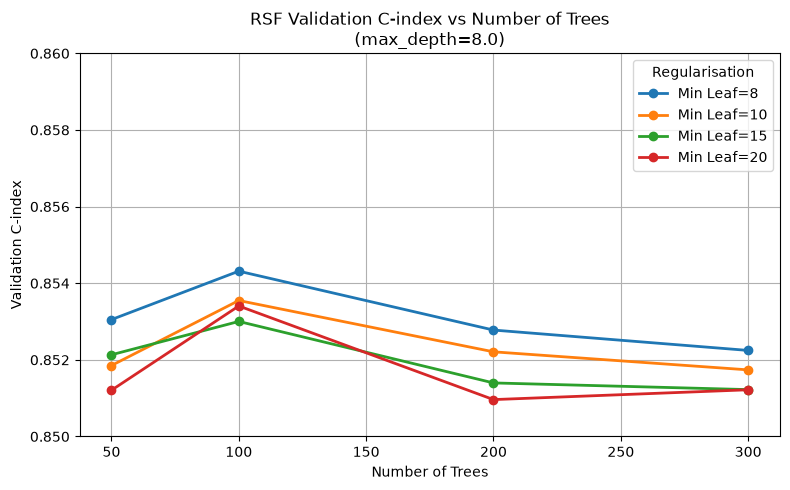

In [77]:

# 5. Plot Performance C-Idnex vs Number of Trees


plt.figure(figsize=(8,5))


# Fix depth for visualisation
subset = results_df[
    results_df["max_depth"].fillna(-1) == 
    (best_params["max_depth"] if pd.notna(best_params["max_depth"]) else -1)
].copy()


for leaf in sorted(subset["min_samples_leaf"].unique()):

    leaf_subset = subset[
        subset["min_samples_leaf"] == leaf
    ].sort_values("n_estimators")


    plt.plot(
        leaf_subset["n_estimators"],
        leaf_subset["validation_c_index"],
        marker="o",
        linewidth=2,
        label=f"Min Leaf={leaf}"
    )


plt.xlabel("Number of Trees")
plt.ylabel("Validation C-index")
plt.title(
    f"RSF Validation C-index vs Number of Trees\n"
    f"(max_depth={best_params['max_depth']})"
)

plt.ylim(0.85, 0.86)
plt.legend(title="Regularisation")
plt.grid(True)

plt.tight_layout()
plt.show()

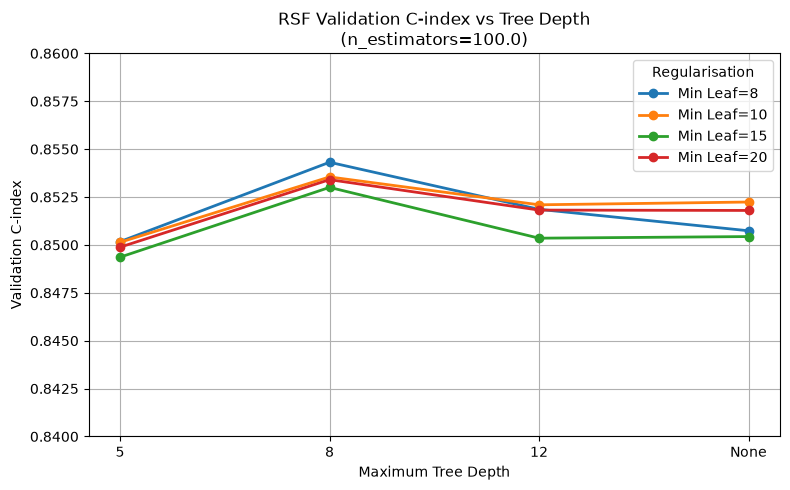

In [78]:

# 6. Plot Performance C-Index vs Tree Depth


plt.figure(figsize=(8,5))


# Fix number of trees for visualisation
subset = results_df[
    results_df["n_estimators"] == best_params["n_estimators"]
].copy()


# Convert max_depth safely to strings
subset["depth_label"] = subset["max_depth"].apply(
    lambda x: "None" if pd.isna(x) else str(int(x))
)


# Define desired order
depth_order = ["5", "8", "12", "None"]


for leaf in sorted(subset["min_samples_leaf"].unique()):

    leaf_subset = subset[
        subset["min_samples_leaf"] == leaf
    ].copy()


    # Keep depth ordering consistent
    leaf_subset["depth_label"] = pd.Categorical(
        leaf_subset["depth_label"],
        categories=depth_order,
        ordered=True
    )


    leaf_subset = leaf_subset.sort_values(
        "depth_label"
    )


    plt.plot(
        leaf_subset["depth_label"].astype(str),
        leaf_subset["validation_c_index"].astype(float),
        marker="o",
        linewidth=2,
        label=f"Min Leaf={leaf}"
    )


plt.xlabel("Maximum Tree Depth")
plt.ylabel("Validation C-index")

plt.title(
    f"RSF Validation C-index vs Tree Depth\n"
    f"(n_estimators={best_params['n_estimators']})"
)

plt.ylim(0.84, 0.86)
plt.legend(title="Regularisation")
plt.grid(True)

plt.tight_layout()
plt.show()

---


# 4. Re-Train and Save the full (X-train + X_val) dataset with best HPs

### 4.1. Combine train and validation data

In [79]:
# Combine training and validation data
X_train_final = pd.concat(
    [X_train, X_val],
    axis=0
)

y_train_final = np.concatenate(
    [y_rsf_train, y_rsf_val]
)

### 4.2. Train the FINAL RSF with best params

In [80]:

# Extract best hyperparameters from best_params df - created in section 3.2 step 4 - after we picked the best params from the tuning combos.

best_n_estimators = int(
    best_params["n_estimators"]
)

best_depth = (
    None
    if pd.isna(best_params["max_depth"])
    else int(best_params["max_depth"])
)

best_leaf = int(
    best_params["min_samples_leaf"]
)


print("Final hyperparameters:")
print("Trees:", best_n_estimators)
print("Depth:", best_depth)
print("Min leaf:", best_leaf)


#-----------------------------------------------------------

# FINAL RSF TRAIN:
rsf_final = RandomSurvivalForest(
    n_estimators=best_n_estimators,
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    random_state=42,
    n_jobs=-1
)


rsf_final.fit(
    X_train_final,
    y_train_final
)

print("Final RSF trained")

Final hyperparameters:
Trees: 100
Depth: 8
Min leaf: 8
Final RSF trained


### NOTE

- VALIDATION C-Index: Section 3 (used only for HP Tuning)

    The HP tuning waws performed on a model trained on X_train only followed by validating on X-val. This has its own c-index called the validation c-index which was 0.854315 (See section 3). This enabled us to pick the best hyperparams.

    ---

- FINAL TRAIN SET C-Index: Section 6 (used for final model diagnostics

    As seen in section 4, the Final model was fitted on the larget X_train + X-val = X_train_final dataset. The c-index for this model has been reported in section 6 - model diagnoistics and performance.




### 4.3 Save the FINAL model

In [81]:
import joblib

joblib.dump(
    rsf_final,
    "rsf_final_model.pkl"
)

print("Model saved")

Model saved


---

In [82]:
# rsf_loaded = joblib.load(
#     "rsf_final_model.pkl"
# )

# rsf_loaded.predict(X_new)

---

# 5. Test Set Evalutation

### 5.1 Predict and Evaluate C-index on Test Set using .score()

In [83]:
test_c_index = rsf_final.score(
    X_test,
    y_rsf_test
)


print(
    f"Final Test C-index: {test_c_index:.4f}"
)

Final Test C-index: 0.8480


### 5.2 Compute IBS for Test (not required for Train)

In [84]:
from sksurv.metrics import (
    integrated_brier_score,
    brier_score
)
import numpy as np


# ------------------------------------------------------------
# Define evaluation times
# ------------------------------------------------------------

train_event_times = np.unique(
    y_train_final["tenure"][y_train_final["Churn_flag"]]
)


test_event_times = y_rsf_test["tenure"]


times = train_event_times[
    (train_event_times > test_event_times.min()) &
    (train_event_times < test_event_times.max())
]


print(
    f"Evaluating IBS from month {times.min()} "
    f"to month {times.max()}"
)


# ------------------------------------------------------------
# Predict survival probabilities
# ------------------------------------------------------------

surv_functions = rsf_final.predict_survival_function(
    X_test
)


survival_probs = np.asarray(
    [
        fn(times)
        for fn in surv_functions
    ]
)


print(
    "Survival probability matrix:",
    survival_probs.shape
)


# ------------------------------------------------------------
# IBS
# ------------------------------------------------------------

ibs = integrated_brier_score(
    y_train_final,
    y_rsf_test,
    survival_probs,
    times
)


print(
    f"Final Test IBS: {ibs:.4f}"
)

Evaluating IBS from month 2.0 to month 71.0
Survival probability matrix: (1055, 70)
Final Test IBS: 0.0932


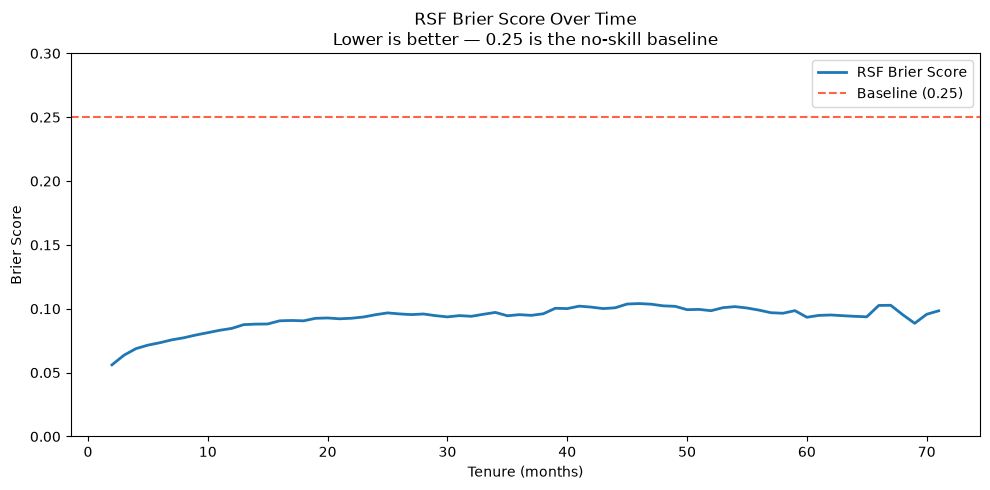

In [85]:
# ── Brier Score Plot with Baseline ────────────────────────────

from sksurv.metrics import brier_score

# Compute Brier Score at each time point
times_bs, bs = brier_score(
    y_train_final,
    y_rsf_test,
    survival_probs,
    times
)


fig, ax = plt.subplots(figsize=(10, 5))

# Model Brier score
ax.plot(
    times_bs,
    bs,
    linewidth=2,
    label="RSF Brier Score"
)

# No-skill baseline
ax.axhline(
    0.25,
    color="tomato",
    linestyle="--",
    linewidth=1.5,
    label="Baseline (0.25)"
)


ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Brier Score")

ax.set_title(
    "RSF Brier Score Over Time\n"
    "Lower is better — 0.25 is the no-skill baseline"
)

ax.set_ylim(0, 0.30)

ax.legend()

plt.tight_layout()
plt.show()

---


# 6. Model Diagnostics and Performance

### 6.1 X_train_final and X-test C-Index

In [86]:
# Train vs Test C-index gap for tuned RSF

train_c_index = rsf_final.score(
    X_train_final,
    y_train_final
)

test_c_index = rsf_final.score(
    X_test,
    y_rsf_test
)

gap = train_c_index - test_c_index


print(f"Train C-index: {train_c_index:.4f}")
print(f"Test C-index : {test_c_index:.4f}")
print(f"Gap          : {gap:.4f}")

Train C-index: 0.8623
Test C-index : 0.8480
Gap          : 0.0143


### 6.2 FINAL RSF MODEL PROPERTIES AND FEATURE IMPORTANCE

=== RSF Model Parameters ===
Number of trees       : 100
Maximum depth         : 8
Minimum samples leaf  : 8
Number of features    : 28

=== Tree Structure ===
Average leaves per tree : 115.2
Minimum leaves per tree : 85
Maximum leaves per tree : 146
Average depth           : 8.0
Minimum depth           : 8
Maximum depth           : 8
Average nodes per tree  : 229.4

=== Leaf Size Analysis ===
Minimum customers per leaf : 8
Average customers per leaf : 32.8
Maximum customers per leaf : 593

Calculating permutation importance...

=== Top 15 Important Features ===


,Feature,Importance,Std
23,Contract_Two year,0.069782,0.009119
22,Contract_One year,0.049807,0.006679
11,OnlineSecurity_Yes,0.013368,0.001884
13,OnlineBackup_Yes,0.010961,0.002547
3,Partner_Yes,0.009928,0.002466
26,PaymentMethod_Electronic check,0.007195,0.002923
17,TechSupport_Yes,0.006764,0.002072
1,MonthlyCharges,0.005935,0.001446
15,DeviceProtection_Yes,0.002188,0.001003
7,MultipleLines_Yes,0.001966,0.001010


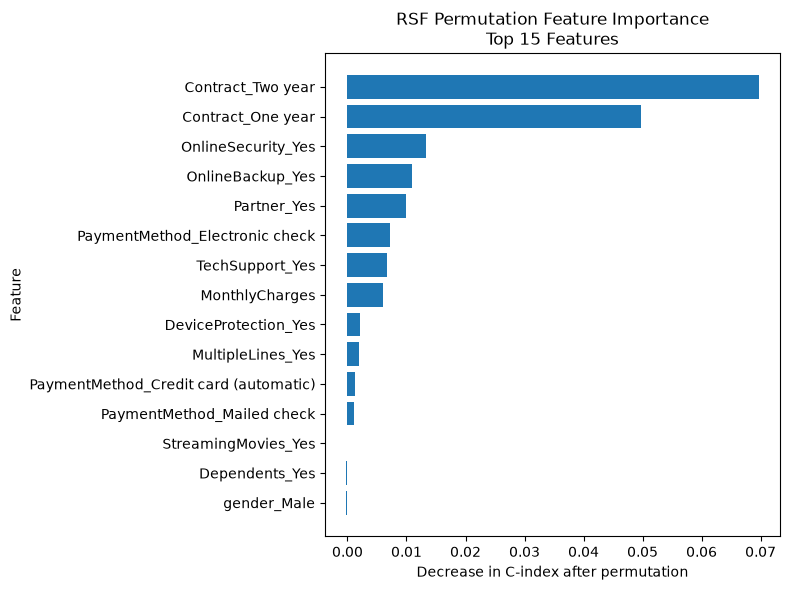


=== Model Performance ===
Train C-index : 0.8623
Test C-index  : 0.8480
Gap           : 0.0143


In [87]:



# ------------------------------------------------------------
# 1. Basic Model Parameters
# ------------------------------------------------------------

print("=== RSF Model Parameters ===")

print(f"Number of trees       : {rsf_final.n_estimators}")
print(f"Maximum depth         : {rsf_final.max_depth}")
print(f"Minimum samples leaf  : {rsf_final.min_samples_leaf}")

print(f"Number of features    : {rsf_final.n_features_in_}")


# ------------------------------------------------------------
# 2. Tree Structure Analysis
# ------------------------------------------------------------

leaf_counts = []
node_counts = []
depths = []

for tree in rsf_final.estimators_:

    # leaf nodes have no children
    is_leaf = (
        tree.tree_.children_left == -1
    )

    leaf_counts.append(
        np.sum(is_leaf)
    )

    node_counts.append(
        tree.tree_.node_count
    )

    depths.append(
        tree.tree_.max_depth
    )


print("\n=== Tree Structure ===")

print(
    f"Average leaves per tree : {np.mean(leaf_counts):.1f}"
)

print(
    f"Minimum leaves per tree : {np.min(leaf_counts)}"
)

print(
    f"Maximum leaves per tree : {np.max(leaf_counts)}"
)

print(
    f"Average depth           : {np.mean(depths):.1f}"
)

print(
    f"Minimum depth           : {np.min(depths)}"
)

print(
    f"Maximum depth           : {np.max(depths)}"
)

print(
    f"Average nodes per tree  : {np.mean(node_counts):.1f}"
)


# ------------------------------------------------------------
# 3. Leaf Size Analysis
# ------------------------------------------------------------

samples_per_leaf = []

for tree in rsf_final.estimators_:

    is_leaf = (
        tree.tree_.children_left == -1
    )

    leaf_samples = (
        tree.tree_.n_node_samples[is_leaf]
    )

    samples_per_leaf.extend(
        leaf_samples
    )


print("\n=== Leaf Size Analysis ===")

print(
    f"Minimum customers per leaf : {np.min(samples_per_leaf)}"
)

print(
    f"Average customers per leaf : {np.mean(samples_per_leaf):.1f}"
)

print(
    f"Maximum customers per leaf : {np.max(samples_per_leaf)}"
)

# ------------------------------------------------------------
# 4. Permutation Feature Importance
# ------------------------------------------------------------

from sklearn.inspection import permutation_importance


print("\nCalculating permutation importance...")


perm_importance = permutation_importance(
    rsf_final,
    X_test,
    y_rsf_test,
    n_repeats=20,
    random_state=42,
    scoring=None,
    n_jobs=-1
)


feature_importance = pd.DataFrame(
    {
        "Feature": X_test.columns,
        "Importance": perm_importance.importances_mean,
        "Std": perm_importance.importances_std
    }
)


feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)


print("\n=== Top 15 Important Features ===")

display(
    feature_importance.head(15)
)

# ------------------------------------------------------------
# Feature Importance Plot
# ------------------------------------------------------------

top_features = feature_importance.head(15)


plt.figure(figsize=(8,6))


plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)


plt.xlabel(
    "Decrease in C-index after permutation"
)

plt.ylabel(
    "Feature"
)


plt.title(
    "RSF Permutation Feature Importance\nTop 15 Features"
)


plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Model Performance
# ------------------------------------------------------------

train_c = rsf_final.score(
    X_train_final,
    y_train_final
)


test_c = rsf_final.score(
    X_test,
    y_rsf_test
)


print("\n=== Model Performance ===")

print(
    f"Train C-index : {train_c:.4f}"
)

print(
    f"Test C-index  : {test_c:.4f}"
)

print(
    f"Gap           : {train_c-test_c:.4f}"
)

our dissertation:

You can write:

"Feature importance was assessed using permutation importance rather than impurity-based importance, as Random Survival Forests implemented in scikit-survival do not expose traditional feature importance scores. Each feature was randomly permuted, and the reduction in concordance index was measured. Features causing the largest decrease in predictive performance were considered the most influential."

One caution: because your dataset is Telco churn, many features are correlated:

Example:

MonthlyCharges
TotalCharges
Tenure
Contract type

Permutation importance can underestimate importance when features are correlated because another correlated feature can compensate after shuffling.

But for a project/report, permutation importance is absolutely the right choice here.

---

# 7. Benchmarking with the Kaplan Meier Model

In [88]:
from sksurv.nonparametric import kaplan_meier_estimator

# ------------------------------------------------------------
# Population-level KM: one single curve, no features at all.
# Fit on the SAME data your final RSF/xgbse models were fit on
# (train + val combined) — apples-to-apples benchmark.
# ------------------------------------------------------------

km_times, km_survival = kaplan_meier_estimator(
    y_train_final["Churn_flag"], y_train_final["tenure"]
)

In [89]:
# ------------------------------------------------------------
# Give EVERY test customer the identical KM curve (no personalization),
# evaluated on the exact same `times` grid used for RSF's IBS above.
# ------------------------------------------------------------

km_surv_at_times = np.interp(times, km_times, km_survival)
survival_probs_km = np.tile(km_surv_at_times, (len(y_rsf_test), 1))

print("KM survival probability matrix:", survival_probs_km.shape)

KM survival probability matrix: (1055, 70)


In [92]:
# ------------------------------------------------------------
# IBS for population KM — same function, same test set, same times
# ------------------------------------------------------------

ibs_km = integrated_brier_score(
    y_train_final, y_rsf_test, survival_probs_km, times
)

print(f"Population KM Test IBS: {ibs_km:.4f}")

Population KM Test IBS: 0.1760


In [93]:
from sksurv.metrics import concordance_index_censored

# Population KM gives everyone an identical prediction, so there's no
# basis to rank anyone above anyone else -> guaranteed 0.5, always.
identical_risk_score = np.zeros(len(y_rsf_test))
c_index_km = concordance_index_censored(
    y_rsf_test["Churn_flag"].astype(bool), y_rsf_test["tenure"], identical_risk_score
)[0]

print(f"Population KM Test C-index: {c_index_km:.4f}")

Population KM Test C-index: 0.5000


---

# 8. Pre-depolyment Application Analysis

### 8.1 Objective

The end goal of this project is a deployable application built around rsf_final_model, offering two modes of use:

* Mode A — Batch analysis: upload a CSV of customers, set a churn probability threshold based on business requirements and a time window, and get back the customers to target for a retention campaign.

* Mode B — Single customer: enter one customer's details and receive a Low/Medium/High risk classification, along with a survival curve plotted against reference examples of what a customer in each risk tier typically looks like.

**Mode B's reference curves require identifying a representative real customer for each risk tier — not a hypothetical profile, but an actual customer from the data whose predicted risk sits near the middle of that tier's range. Before that's possible, the risk tiers themselves need to be defined.**

---

#### 8.2 Defining the risk measure

To construct the risk tiers, the final RSF model was applied to the complete dataset of 7,032 customers (justified at the end of this section). For each customer, the model produced an individual survival curve, $S(t \mid X)$.

A **12-month horizon** was then selected. The customer's predicted probability of churn by month 12 was calculated as:

$$
P(T \leq 12 \mid X) = 1 - S(12 \mid X)
$$

This produces one churn-probability score for every customer. For example, a predicted probability of 8% means that the model's estimated probability of this customer churning by month 12 is 8%.

There are therefore two distinct levels of analysis:

1. **Individual level:** each customer receives a predicted 12-month churn probability expressed as a percentage.
2. **Population level:** the distribution of these individual probabilities is examined across all 7,032 customers.

The second layer is what allows the risk bands to be defined.

---

#### 8.3 Examining the probability distribution

Before assigning customers to Low, Medium, or High risk, the distribution of predicted 12-month churn probabilities was examined using summary statistics, probability bands, and visualizations.

The probabilities were first grouped into bands such as:

- 0–10%
- 10–20%
- 20–30%
- 30–40%
- 40–50%
- 50–60%
- 60–70%
- etc.

The number and percentage of customers falling into each band were then calculated.

This step was important because the risk thresholds should reflect the probabilities that the model actually produces. For example, simply declaring **60%+ as "High Risk"** would be unhelpful if almost no customers ever receive a predicted probability that high. Examining the distribution first prevents arbitrary thresholds from creating empty or meaningless risk categories.

12-month churn probability distribution:
  Min:    0.0%
  Mean:   16.8%
  Median: 11.7%
  Max:    60.2%

Quartiles:
  Q1 (p25): 2.2%
  Q2 (p50): 11.7%
  Q3 (p75): 27.1%

12-month churn probability, by band:
      0% - 10% :  3310 customers  (47.1%)
     10% - 20% :  1093 customers  (15.5%)
     20% - 30% :  1073 customers  (15.3%)
     30% - 40% :   676 customers  (9.6%)
     40% - 50% :   525 customers  (7.5%)
     50% - 60% :   354 customers  (5.0%)
     60% - 70% :     1 customers  (0.0%)
     70% - 80% :     0 customers  (0.0%)
     80% - 90% :     0 customers  (0.0%)
    90% - 100% :     0 customers  (0.0%)


/var/folders/s3/mby87d114_g07sh3cl6ysz2r0000gn/T/ipykernel_62844/2366325571.py:38: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax2.boxplot(churn_probs_12mo, vert=True, patch_artist=True,


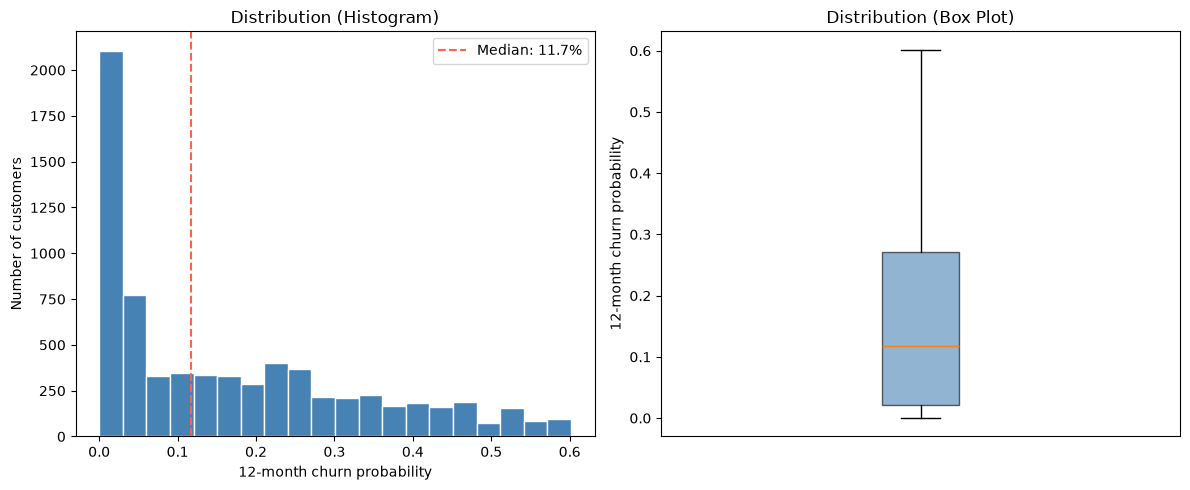

In [90]:

# 12-month churn probability for every customer in X, as a brand-new customer
t = 12
surv_funcs = rsf_final.predict_survival_function(X, return_array=False)
churn_probs_12mo = np.array([1 - fn(t) for fn in surv_funcs])

# --- Core stats ---
print("12-month churn probability distribution:")
print(f"  Min:    {churn_probs_12mo.min():.1%}")
print(f"  Mean:   {churn_probs_12mo.mean():.1%}")
print(f"  Median: {np.median(churn_probs_12mo):.1%}")
print(f"  Max:    {churn_probs_12mo.max():.1%}")
print()
print("Quartiles:")
for p in [25, 50, 75]:
    print(f"  Q{p//25 if p!=50 else 2} (p{p}): {np.percentile(churn_probs_12mo, p):.1%}")

# --- Banded breakdown ---
bin_edges = [0.0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]
bin_labels = [f"{int(bin_edges[i]*100)}% - {int(bin_edges[i+1]*100)}%" for i in range(len(bin_edges)-1)]
binned = pd.cut(churn_probs_12mo, bins=bin_edges, labels=bin_labels, include_lowest=True)
counts = binned.value_counts().sort_index()
fractions = counts / len(churn_probs_12mo)

print("\n12-month churn probability, by band:")
for band, count in counts.items():
    print(f"  {band:>12} : {count:>5} customers  ({fractions[band]:.1%})")

# --- Histogram + box plot side by side ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.hist(churn_probs_12mo, bins=20, color="steelblue", edgecolor="white")
ax1.axvline(np.median(churn_probs_12mo), color="tomato", linestyle="--", label=f"Median: {np.median(churn_probs_12mo):.1%}")
ax1.set_xlabel("12-month churn probability")
ax1.set_ylabel("Number of customers")
ax1.set_title("Distribution (Histogram)")
ax1.legend()

ax2.boxplot(churn_probs_12mo, vert=True, patch_artist=True,
            boxprops=dict(facecolor="steelblue", alpha=0.6))
ax2.set_ylabel("12-month churn probability")
ax2.set_title("Distribution (Box Plot)")
ax2.set_xticks([])

plt.tight_layout()
plt.show()

---

#### 8.4 Establishing the Low / Medium / High risk tiers and choosing Representative Customers

The observed probability distribution was then used to define three populated risk bands:

- **Low Risk:** customers with the lowest predicted probability of churn within 12 months. *Set here as < 10%*
- **Medium Risk:** customers with an intermediate predicted probability of churn within 12 months. *Set here as 10% < P < 20%*
- **High Risk:** customers with the highest predicted probability of churn within 12 months. *Set here as P >20%*

*These thresholds are intended as **business-facing categories**, rather than additional model parameters, and can therefore be changed from model.py as per evolving business requirements*. 

The RSF produces the underlying probability; the risk bands provide a simpler way for a business user to interpret and act on that probability.

Once the bands were established, actual customers falling within each band could be identified. **A representative customer from each tier can then be selected to provide the reference survival curves used in Mode B of the application.**

In [91]:


bands = {
    "Example: Low risk": (0.00, 0.10),
    "Example: Medium risk": (0.10, 0.30),
    "Example: High risk": (0.30, 1.00),
}

raw_feature_cols = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod", "MonthlyCharges",
]

print("REFERENCE_PROFILES = {")
for label, (low, high) in bands.items():
    mask = (churn_probs_12mo >= low) & (churn_probs_12mo < high)
    band_df = df[mask]
    band_probs = churn_probs_12mo[mask]

    median_prob = np.median(band_probs)
    closest_idx = np.argmin(np.abs(band_probs - median_prob))
    representative = band_df.iloc[closest_idx]
    actual_prob = band_probs[closest_idx]

    print(f'    "{label}": {{  # actual 12-month churn prob: {actual_prob:.1%}')
    for col in raw_feature_cols:
        val = representative[col]
        if isinstance(val, str):
            print(f'        "{col}": "{val}",')
        else:
            print(f'        "{col}": {val},')
    print("    },")
print("}")

REFERENCE_PROFILES = {
    "Example: Low risk": {  # actual 12-month churn prob: 1.9%
        "gender": "Female",
        "SeniorCitizen": 0,
        "Partner": "No",
        "Dependents": "No",
        "PhoneService": "Yes",
        "MultipleLines": "No",
        "InternetService": "No",
        "OnlineSecurity": "No internet service",
        "OnlineBackup": "No internet service",
        "DeviceProtection": "No internet service",
        "TechSupport": "No internet service",
        "StreamingTV": "No internet service",
        "StreamingMovies": "No internet service",
        "Contract": "Two year",
        "PaperlessBilling": "Yes",
        "PaymentMethod": "Bank transfer (automatic)",
        "MonthlyCharges": 20.75,
    },
    "Example: Medium risk": {  # actual 12-month churn prob: 19.9%
        "gender": "Female",
        "SeniorCitizen": 0,
        "Partner": "No",
        "Dependents": "Yes",
        "PhoneService": "Yes",
        "MultipleLines": "No",
        "InternetServ

These customers were then manually coded in Mode B of model.py as the reference customers to be plotted along side the KM curve of a new test customer. The new customer's KM curve can then be benchmarked against the KM curves of a typical/ random low - medium - high risk customer's KM curve.

---

### 8.5 Justifications and Caveat

1. The decision of splitting customers into low/ medium/ high churn risk AFTER the model has predicted their probaiility of churn/survival by time T, is a Business Decision. If this were a modeling decision, for example if this affected our choice of hyper params, then we would have to be cautious about which 'X' - train, test or val, to use for this analysis. Right now all we needed for was the largest population available to us that could help us visualise the fraction of customers available in each P(Churn) bank and then assign them to low/med/high risk brackets.

2. A 12-month horizon was selected as the common reference point for this analysis. This provides a simple annual measure of churn risk that can be used consistently across customers and is naturally aligned with business planning, contracts, retention campaigns, and annual customer-management cycles. 

The same framework can later be extended to other horizons if required. For example, the batch application could allow a business user to specify a different time window depending on the retention campaign being considered.

3. Caveat worth noting: since roughly 85% of this population was also used to fit the model, predicted probabilities on those rows may be marginally more confident than on genuinely unseen customers. This is an acceptable limitation for a policy-calibration exercise, though it would be inappropriate if this population were being used to claim model performance.

---